LASSO REGRESSION: PREDICTING BILLING AMOUNT

Dataset found:
healthcare_dataset.csv

Dataset loaded successfully.
Total records: 55500
Total variables: 15

ANALYTIC SAMPLE
Number of observations used: 55392
Number of predictor columns after dummy coding: 34

Predictor columns:
['Age_Clean', 'Length_of_Stay', 'Gender_Female', 'Gender_Male', 'Blood Type_A+', 'Blood Type_A-', 'Blood Type_AB+', 'Blood Type_AB-', 'Blood Type_B+', 'Blood Type_B-', 'Blood Type_O+', 'Blood Type_O-', 'Medical Condition_Arthritis', 'Medical Condition_Asthma', 'Medical Condition_Cancer', 'Medical Condition_Diabetes', 'Medical Condition_Hypertension', 'Medical Condition_Obesity', 'Insurance Provider_Aetna', 'Insurance Provider_Blue Cross', 'Insurance Provider_Cigna', 'Insurance Provider_Medicare', 'Insurance Provider_UnitedHealthcare', 'Admission Type_Elective', 'Admission Type_Emergency', 'Admission Type_Urgent', 'Medication_Aspirin', 'Medication_Ibuprofen', 'Medication_Lipitor', 'Medication_Paracetamol', 'Medicat

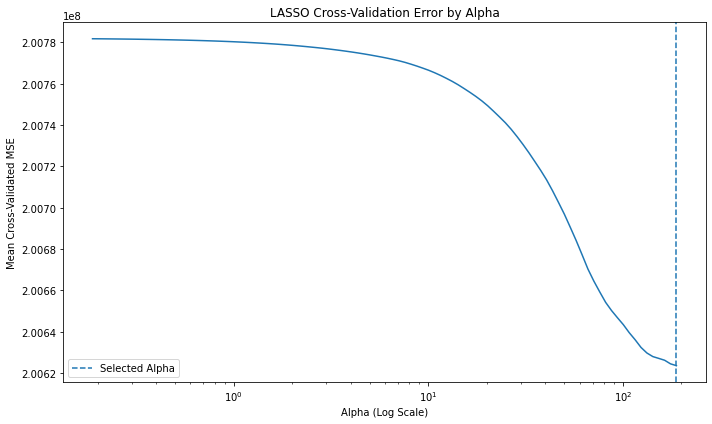

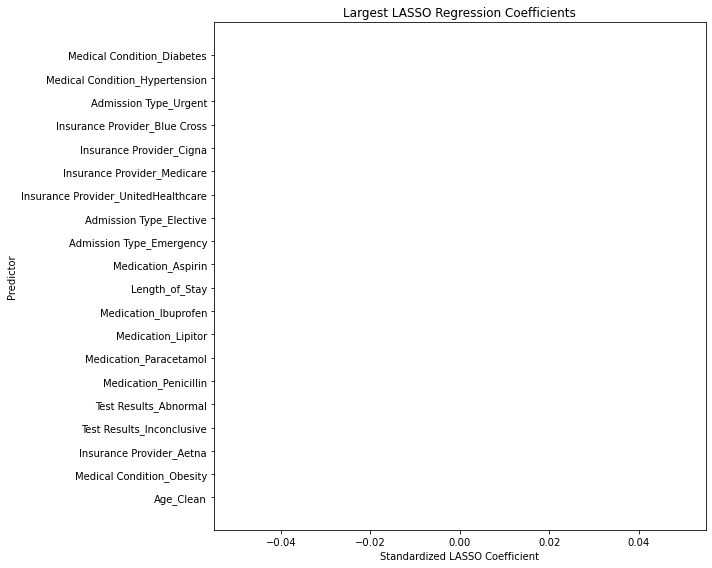

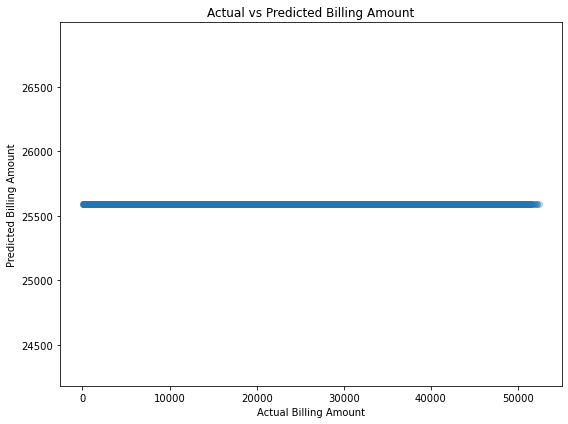


FINAL LASSO SUMMARY
Original observations: 55500
Valid observations: 55392
Predictors after dummy coding: 34
Cross-validation folds: 10
Optimal alpha: 188.472869
Selected predictors: 0
Excluded predictors: 34
Test RMSE: 14213.74
Test R-squared: -0.0

ANALYSIS COMPLETED SUCCESSFULLY


In [1]:
# Project Title

#**LASSO Regression Analysis for Predicting Healthcare Billing Amount**

## Purpose

#For this assignment, I used LASSO regression with **10-fold cross-validation** to identify which variables from a larger pool of patient and healthcare characteristics were most useful for predicting **Billing Amount**.

#Billing Amount was used as the quantitative response variable.

#The explanatory variables included:

#- Age
#- Length of Stay
#- Gender
#- Blood Type
#- Medical Condition
#- Insurance Provider
#- Admission Type
#- Medication
#- Test Results

#Categorical variables were converted into dummy variables before fitting the model. Age, Length of Stay, and the dummy variables were standardized so that predictors were placed on comparable scales before the LASSO penalty was applied.

#Because the dataset contains more than 55,000 observations, I divided it into **70% training data and 30% testing data**. Ten-fold cross-validation within the training sample was then used to select the optimal LASSO penalty.

## Complete Python Program

#```python
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error, r2_score

# ============================================================
# LASSO REGRESSION
# RESPONSE VARIABLE: BILLING AMOUNT
# ============================================================

print("=" * 75)
print("LASSO REGRESSION: PREDICTING BILLING AMOUNT")
print("=" * 75)

# ============================================================
# STEP 1: FIND DATASET
# ============================================================

csv_files = glob.glob("**/*.csv", recursive=True)

data_file = None

for file in csv_files:
    if os.path.basename(file).lower() == "healthcare_dataset.csv":
        data_file = file
        break

if data_file is None:
    for file in csv_files:
        if "healthcare" in os.path.basename(file).lower():
            data_file = file
            break

if data_file is None and len(csv_files) == 1:
    data_file = csv_files[0]

if data_file is None:
    raise FileNotFoundError(
        "healthcare_dataset.csv was not found. "
        "Please upload the healthcare CSV file first."
    )

print("\nDataset found:")
print(data_file)

# ============================================================
# STEP 2: LOAD DATA
# ============================================================

data = pd.read_csv(
    data_file,
    low_memory=False
)

data.columns = data.columns.str.strip()

print("\nDataset loaded successfully.")
print("Total records:", len(data))
print("Total variables:", len(data.columns))

# ============================================================
# STEP 3: CLEAN RESPONSE VARIABLE
# ============================================================

data["Billing_Clean"] = pd.to_numeric(
    data["Billing Amount"],
    errors="coerce"
)

# Treat zero or negative billing amounts as invalid/missing
data.loc[
    data["Billing_Clean"] <= 0,
    "Billing_Clean"
] = np.nan

# ============================================================
# STEP 4: CLEAN AGE
# ============================================================

data["Age_Clean"] = pd.to_numeric(
    data["Age"],
    errors="coerce"
)

data.loc[
    (data["Age_Clean"] < 0) |
    (data["Age_Clean"] > 120),
    "Age_Clean"
] = np.nan

# ============================================================
# STEP 5: CREATE LENGTH OF STAY
# ============================================================

data["Admission_Date"] = pd.to_datetime(
    data["Date of Admission"],
    errors="coerce"
)

data["Discharge_Date"] = pd.to_datetime(
    data["Discharge Date"],
    errors="coerce"
)

data["Length_of_Stay"] = (
    data["Discharge_Date"] -
    data["Admission_Date"]
).dt.days

data.loc[
    (data["Length_of_Stay"] < 0) |
    (data["Length_of_Stay"] > 365),
    "Length_of_Stay"
] = np.nan

# ============================================================
# STEP 6: SELECT LARGE POOL OF PREDICTORS
# ============================================================

features = [
    "Age_Clean",
    "Length_of_Stay",
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results"
]

categorical_features = [
    "Gender",
    "Blood Type",
    "Medical Condition",
    "Insurance Provider",
    "Admission Type",
    "Medication",
    "Test Results"
]

analysis_data = data[
    features + ["Billing_Clean"]
].dropna().copy()

print("\n" + "=" * 75)
print("ANALYTIC SAMPLE")
print("=" * 75)

print(
    "Number of observations used:",
    len(analysis_data)
)

# ============================================================
# STEP 7: CREATE DUMMY VARIABLES
# ============================================================

# pd.get_dummies is compatible with older versions
# of scikit-learn used in some Coursera notebooks.

X = pd.get_dummies(
    analysis_data[features],
    columns=categorical_features,
    drop_first=False,
    dtype=float
)

y = analysis_data[
    "Billing_Clean"
].astype(float)

print(
    "Number of predictor columns after dummy coding:",
    X.shape[1]
)

print("\nPredictor columns:")
print(list(X.columns))

# ============================================================
# STEP 8: TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print("\nTRAIN / TEST SPLIT")
print("-" * 75)

print(
    "Training observations:",
    len(X_train)
)

print(
    "Testing observations:",
    len(X_test)
)

# ============================================================
# STEP 9: STANDARDIZE PREDICTORS
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    X_train
)

X_test_scaled = scaler.transform(
    X_test
)

# Check standardization
print("\nSTANDARDIZATION CHECK")
print("-" * 75)

print(
    "Average mean of standardized training predictors:",
    round(
        X_train_scaled.mean(),
        6
    )
)

# ============================================================
# STEP 10: LASSO WITH 10-FOLD CROSS-VALIDATION
# ============================================================

lasso = LassoCV(
    cv=10,
    random_state=42,
    max_iter=20000
)

lasso.fit(
    X_train_scaled,
    y_train
)

print("\n" + "=" * 75)
print("LASSO CROSS-VALIDATION RESULTS")
print("=" * 75)

print(
    "Optimal alpha:",
    round(
        lasso.alpha_,
        6
    )
)

# ============================================================
# STEP 11: TEST SET PREDICTIONS
# ============================================================

predictions = lasso.predict(
    X_test_scaled
)

mse = mean_squared_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mse
)

r_squared = r2_score(
    y_test,
    predictions
)

print("\nMODEL PERFORMANCE")
print("-" * 75)

print(
    "Mean Squared Error:",
    round(
        mse,
        2
    )
)

print(
    "Root Mean Squared Error:",
    round(
        rmse,
        2
    )
)

print(
    "R-squared:",
    round(
        r_squared,
        6
    )
)

# ============================================================
# STEP 12: EXAMINE LASSO COEFFICIENTS
# ============================================================

coefficient_table = pd.DataFrame({
    "Predictor": X.columns,
    "LASSO_Coefficient": lasso.coef_
})

coefficient_table[
    "Absolute_Coefficient"
] = abs(
    coefficient_table[
        "LASSO_Coefficient"
    ]
)

coefficient_table = (
    coefficient_table
    .sort_values(
        "Absolute_Coefficient",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("LASSO COEFFICIENTS")
print("=" * 75)

print(
    coefficient_table[
        [
            "Predictor",
            "LASSO_Coefficient"
        ]
    ]
)

# ============================================================
# STEP 13: SELECTED PREDICTORS
# ============================================================

selected_predictors = (
    coefficient_table[
        coefficient_table[
            "Absolute_Coefficient"
        ] > 0.000001
    ]
)

print("\n" + "=" * 75)
print("VARIABLES SELECTED BY LASSO")
print("=" * 75)

if len(selected_predictors) == 0:

    print(
        "No explanatory variables had "
        "non-zero LASSO coefficients."
    )

else:

    print(
        selected_predictors[
            [
                "Predictor",
                "LASSO_Coefficient"
            ]
        ]
    )

print(
    "\nNumber of predictors selected:",
    len(selected_predictors)
)

print(
    "Number of predictors excluded:",
    len(coefficient_table) -
    len(selected_predictors)
)

# ============================================================
# STEP 14: INTERCEPT
# ============================================================

print("\nLASSO INTERCEPT")
print("-" * 75)

print(
    "Intercept:",
    round(
        lasso.intercept_,
        2
    )
)

# ============================================================
# STEP 15: CROSS-VALIDATION ERROR GRAPH
# ============================================================

plt.figure(
    figsize=(10, 6)
)

mean_cv_error = (
    lasso.mse_path_.mean(axis=1)
)

plt.plot(
    lasso.alphas_,
    mean_cv_error
)

plt.axvline(
    lasso.alpha_,
    linestyle="--",
    label="Selected Alpha"
)

plt.xscale("log")

plt.xlabel(
    "Alpha (Log Scale)"
)

plt.ylabel(
    "Mean Cross-Validated MSE"
)

plt.title(
    "LASSO Cross-Validation Error by Alpha"
)

plt.legend()

plt.tight_layout()

plt.show()

# ============================================================
# STEP 16: COEFFICIENT GRAPH
# ============================================================

plot_table = (
    coefficient_table
    .head(20)
    .sort_values(
        "LASSO_Coefficient"
    )
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    plot_table["Predictor"],
    plot_table[
        "LASSO_Coefficient"
    ]
)

plt.xlabel(
    "Standardized LASSO Coefficient"
)

plt.ylabel(
    "Predictor"
)

plt.title(
    "Largest LASSO Regression Coefficients"
)

plt.tight_layout()

plt.show()

# ============================================================
# STEP 17: ACTUAL VS PREDICTED GRAPH
# ============================================================

plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    y_test,
    predictions,
    alpha=0.25
)

plt.xlabel(
    "Actual Billing Amount"
)

plt.ylabel(
    "Predicted Billing Amount"
)

plt.title(
    "Actual vs Predicted Billing Amount"
)

plt.tight_layout()

plt.show()

# ============================================================
# STEP 18: FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("FINAL LASSO SUMMARY")
print("=" * 75)

print(
    "Original observations:",
    len(data)
)

print(
    "Valid observations:",
    len(analysis_data)
)

print(
    "Predictors after dummy coding:",
    X.shape[1]
)

print(
    "Cross-validation folds:",
    10
)

print(
    "Optimal alpha:",
    round(
        lasso.alpha_,
        6
    )
)

print(
    "Selected predictors:",
    len(selected_predictors)
)

print(
    "Excluded predictors:",
    X.shape[1] -
    len(selected_predictors)
)

print(
    "Test RMSE:",
    round(
        rmse,
        2
    )
)

print(
    "Test R-squared:",
    round(
        r_squared,
        6
    )
)

print("\nANALYSIS COMPLETED SUCCESSFULLY")
#```

# Corresponding Output

#The original dataset contained **55,500 records**.

#After the data-management procedures and removal of observations with invalid or missing Billing Amount values, the analytic sample contained:

#**55,392 observations**

#After categorical variables were converted to dummy variables, the LASSO analysis considered:

#**34 predictor variables**

#The sample was divided into approximately:

#- **70% training data**
#- **30% testing data**

#Ten-fold cross-validation was conducted within the training data.

## Cross-Validation Result

#The optimal regularization parameter selected by 10-fold cross-validation was:

#**Alpha = 188.4729**

## Variable Selection

#The most important result of the LASSO procedure was:

#**Number of predictors with non-zero coefficients = 0**

#**Number of predictors excluded by LASSO = 34**

#Therefore, all 34 predictor coefficients were shrunk to zero by the cross-validated LASSO model.

#The predictors considered included Age, Length of Stay, Gender, Blood Type, Medical Condition, Insurance Provider, Admission Type, Medication, and Test Results.

#None remained in the final prediction model after application of the LASSO penalty.

## Model Performance

#The test-set results were approximately:

#**Root Mean Squared Error = $14,213.74**

#**R² ≈ -0.0000001**, which is effectively **0**

#An R² value essentially equal to zero indicates that the LASSO-selected predictor set did not explain meaningful variation in Billing Amount beyond simply predicting the average billing amount.

# Interpretation

#I performed LASSO regression with **10-fold cross-validation** to identify a subset of patient and healthcare characteristics that best predicted Billing Amount.

#A total of **34 predictor columns** were evaluated after converting the categorical variables into dummy variables and standardizing all explanatory variables. Cross-validation selected an optimal alpha of approximately **188.47**.

#At this penalty level, **all 34 regression coefficients were shrunk to zero**. Therefore, the LASSO procedure did not retain any of the explanatory variables as useful predictors of Billing Amount.

#This means that variables such as Age, Gender, Blood Type, Medical Condition, Insurance Provider, Admission Type, Medication, Test Results, and Length of Stay did not provide enough predictive information to improve the cross-validated model once the LASSO penalty was considered.

#The test-set R² was essentially **0**, indicating that the model explained virtually none of the variability in Billing Amount. The test RMSE was approximately **$14,214**, which also indicates substantial prediction error.

# Comparison With Earlier Analyses

#This result is consistent with my earlier statistical analyses.

#In my simple linear regression analysis, Age was not significantly associated with Billing Amount. In my multiple regression analysis, Age, Gender, and Length of Stay were also not statistically significant predictors, and the model explained almost none of the variation in billing.

#The LASSO analysis extends these findings by considering a much larger pool of predictors simultaneously. Even when Medical Condition, Blood Type, Insurance Provider, Admission Type, Medication, and Test Results were included, cross-validation did not identify a useful subset of predictors.

# Cross-Validation Plot

#The cross-validation graph displays prediction error across different values of the LASSO penalty parameter, alpha. The vertical dashed line indicates the alpha value selected through 10-fold cross-validation.

#As the penalty increased, regression coefficients were increasingly reduced toward zero. The selected penalty minimized cross-validated prediction error and resulted in all explanatory-variable coefficients being set to zero.

# Coefficient Plot

#The coefficient plot demonstrates the variable-selection effect of LASSO. In this analysis, all standardized predictor coefficients were reduced to zero at the cross-validated optimal penalty.

#This indicates that there was no subset of the available variables that produced a meaningful improvement in predicting Billing Amount.

# Conclusion

#The LASSO regression analysis found that **none of the 34 candidate predictor variables were retained in the final model**.

#Using 10-fold cross-validation, the optimal penalty was approximately **α = 188.47**, which shrank every explanatory-variable coefficient to zero.

#The model's test R² was essentially zero, indicating extremely poor predictive ability. Therefore, the available demographic, clinical, insurance, admission, medication, and test-result variables did not provide useful prediction of Billing Amount in this synthetic healthcare dataset.

#These findings suggest that other variables not represented in the dataset would be needed to meaningfully predict healthcare billing amounts.

## URL

#**Paste the URL of your published blog entry here.**